# Computer Vision - P2

### *Carefully read the following instructions before start coding.*

### **Recommended Preparation**

Before starting P2, it is **recommended that you complete the `p2_tutorial` first**. The tutorial introduces the key concepts and steps needed to complete the practice successfully. Completing it beforehand will help you understand the requirements and avoid common mistakes.


==============================================================================================
## **Practice 2: Image Filtering and Edge Detection**


==============================================================================================

### Main Topics

The main topics covered in this **practical exercise** are:

1. **Image smoothing and convolution** — Exercises 2.1, 2.2, 2.3, and 2.4
2. **Edge detection** — Exercises 2.5, 2.6, and 2.7

To complete this practical exercise, you should understand the following concepts:

* Linear filters
* Histograms
* Convolution
* Image edges

For additional information, refer to the following chapters of *Computer Vision: Algorithms and Applications* by Richard Szeliski:

* **Chapter 3 — Image Processing:** Point Operators and Linear Filtering
* **Chapter 4 — Feature Detection and Matching:** Edges
---

## **2.1 RGB histogram visualization**

**a)** Read the image `./images_notebook/plugs.png` and visualize the **RGB image** and each of its channels (**R, G, and B**) separately. Print the **image shape** and **data type**.

<img src="images_notebook/plugs.png">

> Expected output is illustrated below:

<img src="images_notebook/plugsb.jpg">

In [2]:
# Import the required libraries.
from skimage import io
from matplotlib import pyplot as plt
import numpy as np
from skimage import img_as_float
from skimage.color import rgb2gray
import matplotlib.image as mpimg

plugs = mpimg.imread("images_notebook/image.png")

# Create Figure with 4 Subplots
fig = plt.figure(figsize=(10, 4))
fig.add_subplot(1, 4, 1)
plt.imshow(plugs)
plt.axis("off")
plt.title("Original")
fig.add_subplot(1, 4, 2)
plt.imshow(plugs[:,:,0], cmap='gray')
plt.axis("off")
plt.title("Red Channel")
fig.add_subplot(1, 4, 3)
plt.imshow(plugs[:,:,1], cmap='gray')
plt.axis("off")
plt.title("Green Channel")
fig.add_subplot(1, 4, 4)
plt.imshow(plugs[:,:,2], cmap='gray')
plt.axis("off")
plt.title("Blue Channel")

plt.tight_layout()
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'images_notebook/image.png'

**b)** Create a function named `rgb_im_hist(img, nbins=8)` that takes an **RGB image** as input and:

* Displays the **original RGB image**.
* Computes and displays the **histogram of each color channel (R, G, and B)**.
* Converts the image to **grayscale** and displays its histogram.
* Arranges all results **side by side** with appropriate captions.
* Uses `nbins` as an **input parameter** to specify the number of histogram bins. The value of `nbins` can range from **2 to 256**.

> **Note:** Test your function with `nbins = 8, 16, 32, 64, 128,` and `256` to make sure it works correctly for different numbers of histogram bins.

> Expected output is illustrated below (for `nbins=8`):

<img src="images_notebook/rgb_img_hist.jpg">

**Help:** [matplotlib image tutorial](https://matplotlib.org/users/image_tutorial.html)

In [ ]:
def rgb_im_hist(img, nbins=8):
    fig, axes = plt.subplots(1, 5, figsize=(25, 5))
    
    axes[0].imshow(img)
    axes[0].set_title('Original Image')
    axes[0].axis('off')
    
    r_channel = img[:, :, 0].ravel()
    g_channel = img[:, :, 1].ravel()
    b_channel = img[:, :, 2].ravel()
    
    axes[1].hist(r_channel, bins=nbins)
    axes[1].set_title('Red Channel')
    axes[1].set_xlabel('Intensity')
    axes[1].set_ylabel('Frequency')
    
    axes[2].hist(g_channel, bins=nbins)
    axes[2].set_title('Green Channel')
    axes[2].set_xlabel('Intensity')
    axes[2].set_ylabel('Frequency')
    
    axes[3].hist(b_channel, bins=nbins)
    axes[3].set_title('Blue Channel')
    axes[3].set_xlabel('Intensity')
    axes[3].set_ylabel('Frequency')
    
    gray_img = np.dot(img[...,:3], [0.2989, 0.5870, 0.1140])
    axes[4].hist(gray_img.ravel(), bins=nbins)
    axes[4].set_title('Grayscale')
    axes[4].set_xlabel('Intensity')
    axes[4].set_ylabel('Frequency')
    
    plt.tight_layout()
    plt.show()


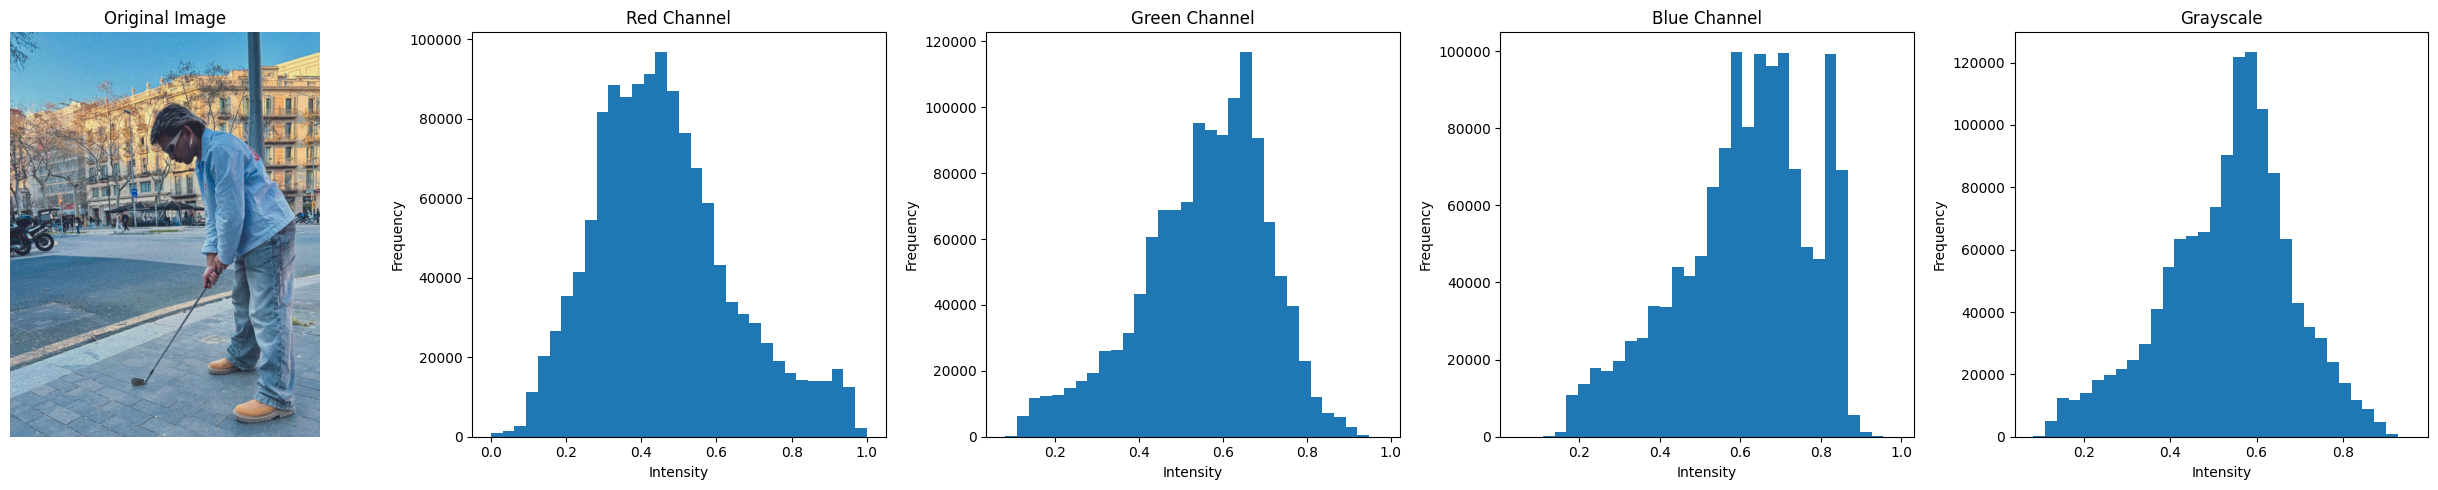

In [ ]:
# Call the function with 32 histogram bins.
rgb_im_hist(plugs, nbins=32)

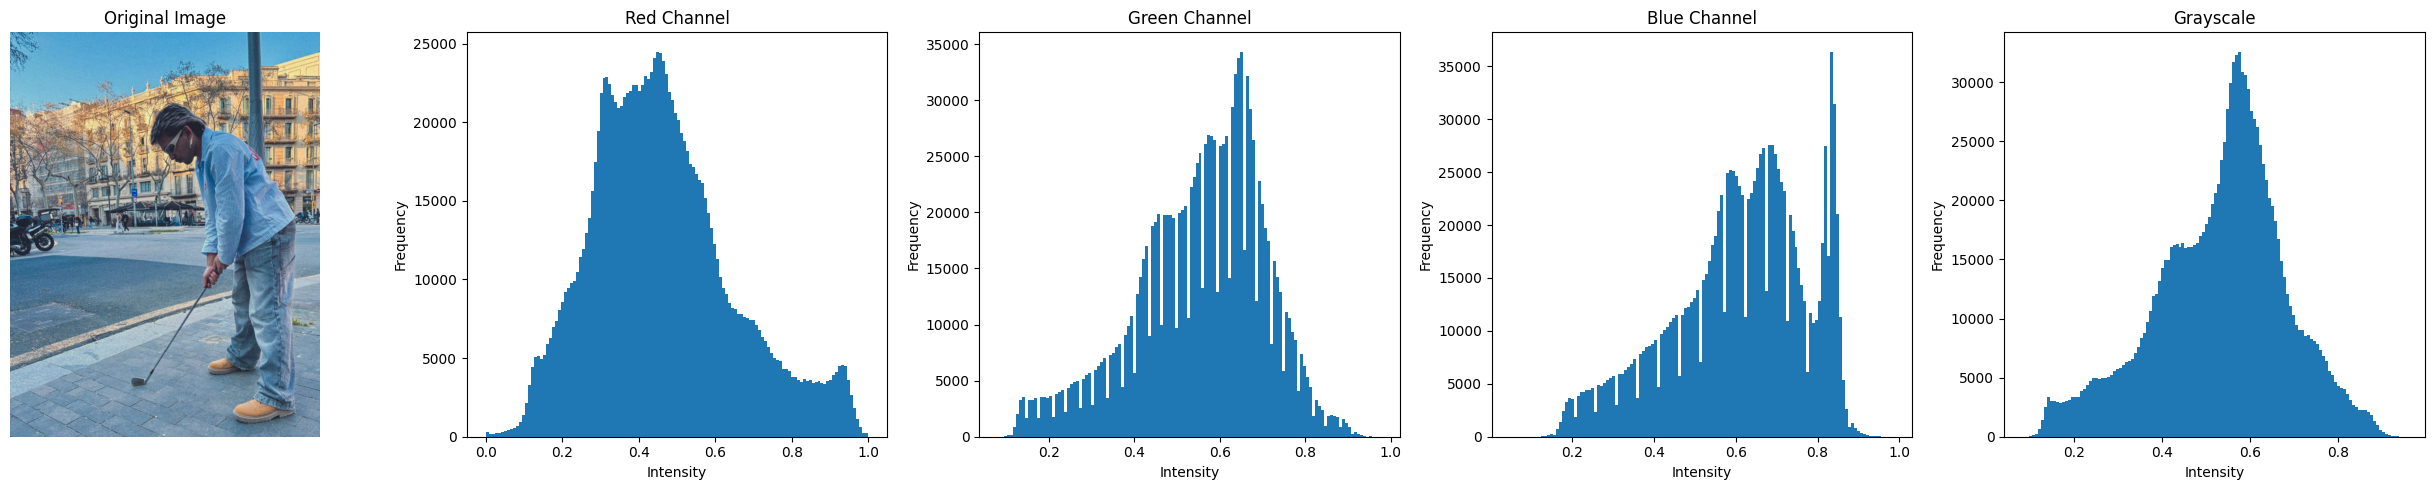

In [ ]:
# Call the function with 128 histogram bins.
rgb_im_hist(plugs, nbins=128)

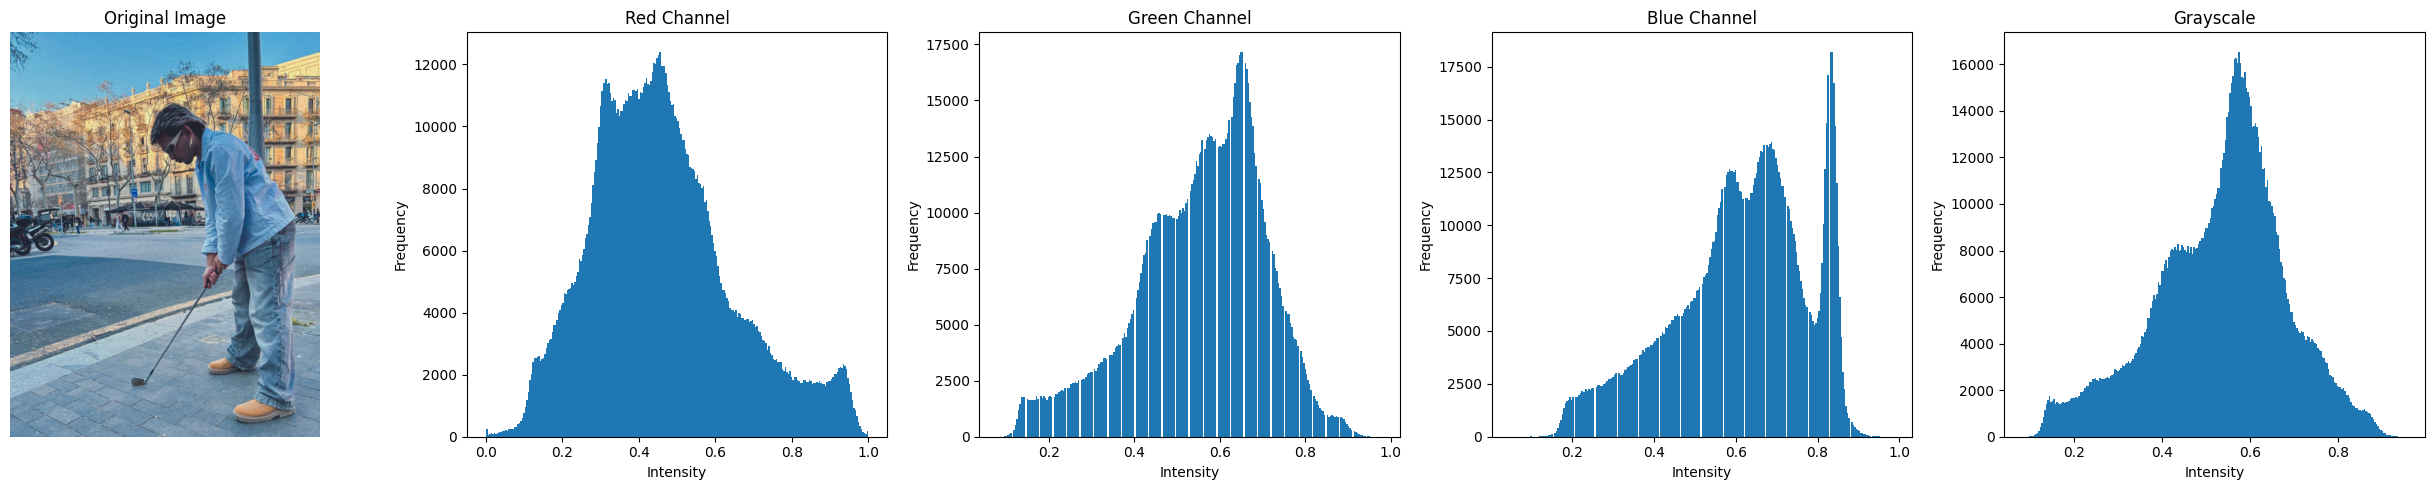

In [ ]:
# Call the function with 256 histogram bins.
rgb_im_hist(plugs, nbins=256)

### Discussion

Analyse the plots obtained with different values of `nbins`. In particular, consider:

* How increasing the number of bins affects the **appearance and level of detail** of the histograms.
* The differences between the histograms of the **R, G, and B channels**.
* The relationship between the **RGB channel histograms** and the **grayscale histogram**.
* Which values of `nbins` provide a more useful representation of the image's intensity distribution.
---

## **2.2 Grayscale and RGB images filtering (convolutions)**

**a)** Read the image `./images_notebook/oryx.png`. Resize the image to **256 × 256 pixels** and convert it to grayscale (store the result as `oryx_gray`).

Apply the following convolutions:

1. Convolve `oryx_gray` with the horizontal mask

   `mask_h1d = [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]`

   using the `ndimage.convolve()` function from the `scipy` package.

2. Convolve `oryx_gray` with the transpose of the mask used in part (1).

3. Convolve `oryx_gray` with a uniform **two-dimensional** mask of size **15 × 15**, where all values are equal to 1.

For each resulting image, determine the **minimum value**, **maximum value**, and **data type**.

**Note:** The `convolve()` function performs **multidimensional convolution**. Therefore, a one-dimensional horizontal mask must be represented as `[[1, ..., 1]]`.

**Note:** Before applying `convolve()`, normalize each mask so that the sum of all its elements is equal to 1.


In [ ]:
from skimage.transform import resize
from scipy.ndimage import convolve
from scipy import ndimage

# REad the image and resize
oryx = mpimg.imread("images_notebook/Milo.jpeg")
oryx_resized = resize(oryx, (256, 256))

# Convert to grayscale
if oryx_resized.ndim >= 3:
    oryx_gray = rgb2gray(oryx_resized[..., :3])
else:
    oryx_gray = oryx_resized

mask_h1d = np.ones((1, 15))
mask_h1d = mask_h1d / np.sum(mask_h1d) # Normalización
conv_h = ndimage.convolve(oryx_gray, mask_h1d)

mask_v1d = mask_h1d.T
conv_v = ndimage.convolve(oryx_gray, mask_v1d)

mask_2d = np.ones((15, 15))
mask_2d = mask_2d / np.sum(mask_2d) # Normalización
conv_2d = ndimage.convolve(oryx_gray, mask_2d)

def print_image_stats(name, img):
    print(f"{name}:")
    print(f"  Min: {img.min():.4f}")
    print(f"  Max: {img.max():.4f}")
    print(f"  Type: {img.dtype}\n")

print_image_stats("Convolución Horizontal", conv_h)
print_image_stats("Convolución Vertical", conv_v)
print_image_stats("Convolución 2D Uniforme", conv_2d)


Convolución Horizontal:
  Min: 0.0569
  Max: 0.9898
  Type: float64

Convolución Vertical:
  Min: 0.0551
  Max: 0.9629
  Type: float64

Convolución 2D Uniforme:
  Min: 0.0683
  Max: 0.9568
  Type: float64



**b)** Visualize the four images—`oryx_gray` and the output of each step from Exercise (a)—in a single figure, using an appropriate title for each image.

Then, consider the following questions:

* Is the data type of the mask important for the convolution operation?
* What effect does each mask have on the original image?
* Compare and discuss the results obtained with the three masks.

**Note:** `matplotlib.pyplot` automatically rescales the image intensity values when displaying an image. Visualize the four images **both with and without intensity-range rescaling** and compare the results.

> Expected output is illustrated below:

<img src="images_notebook/oryx_filtered.jpg">

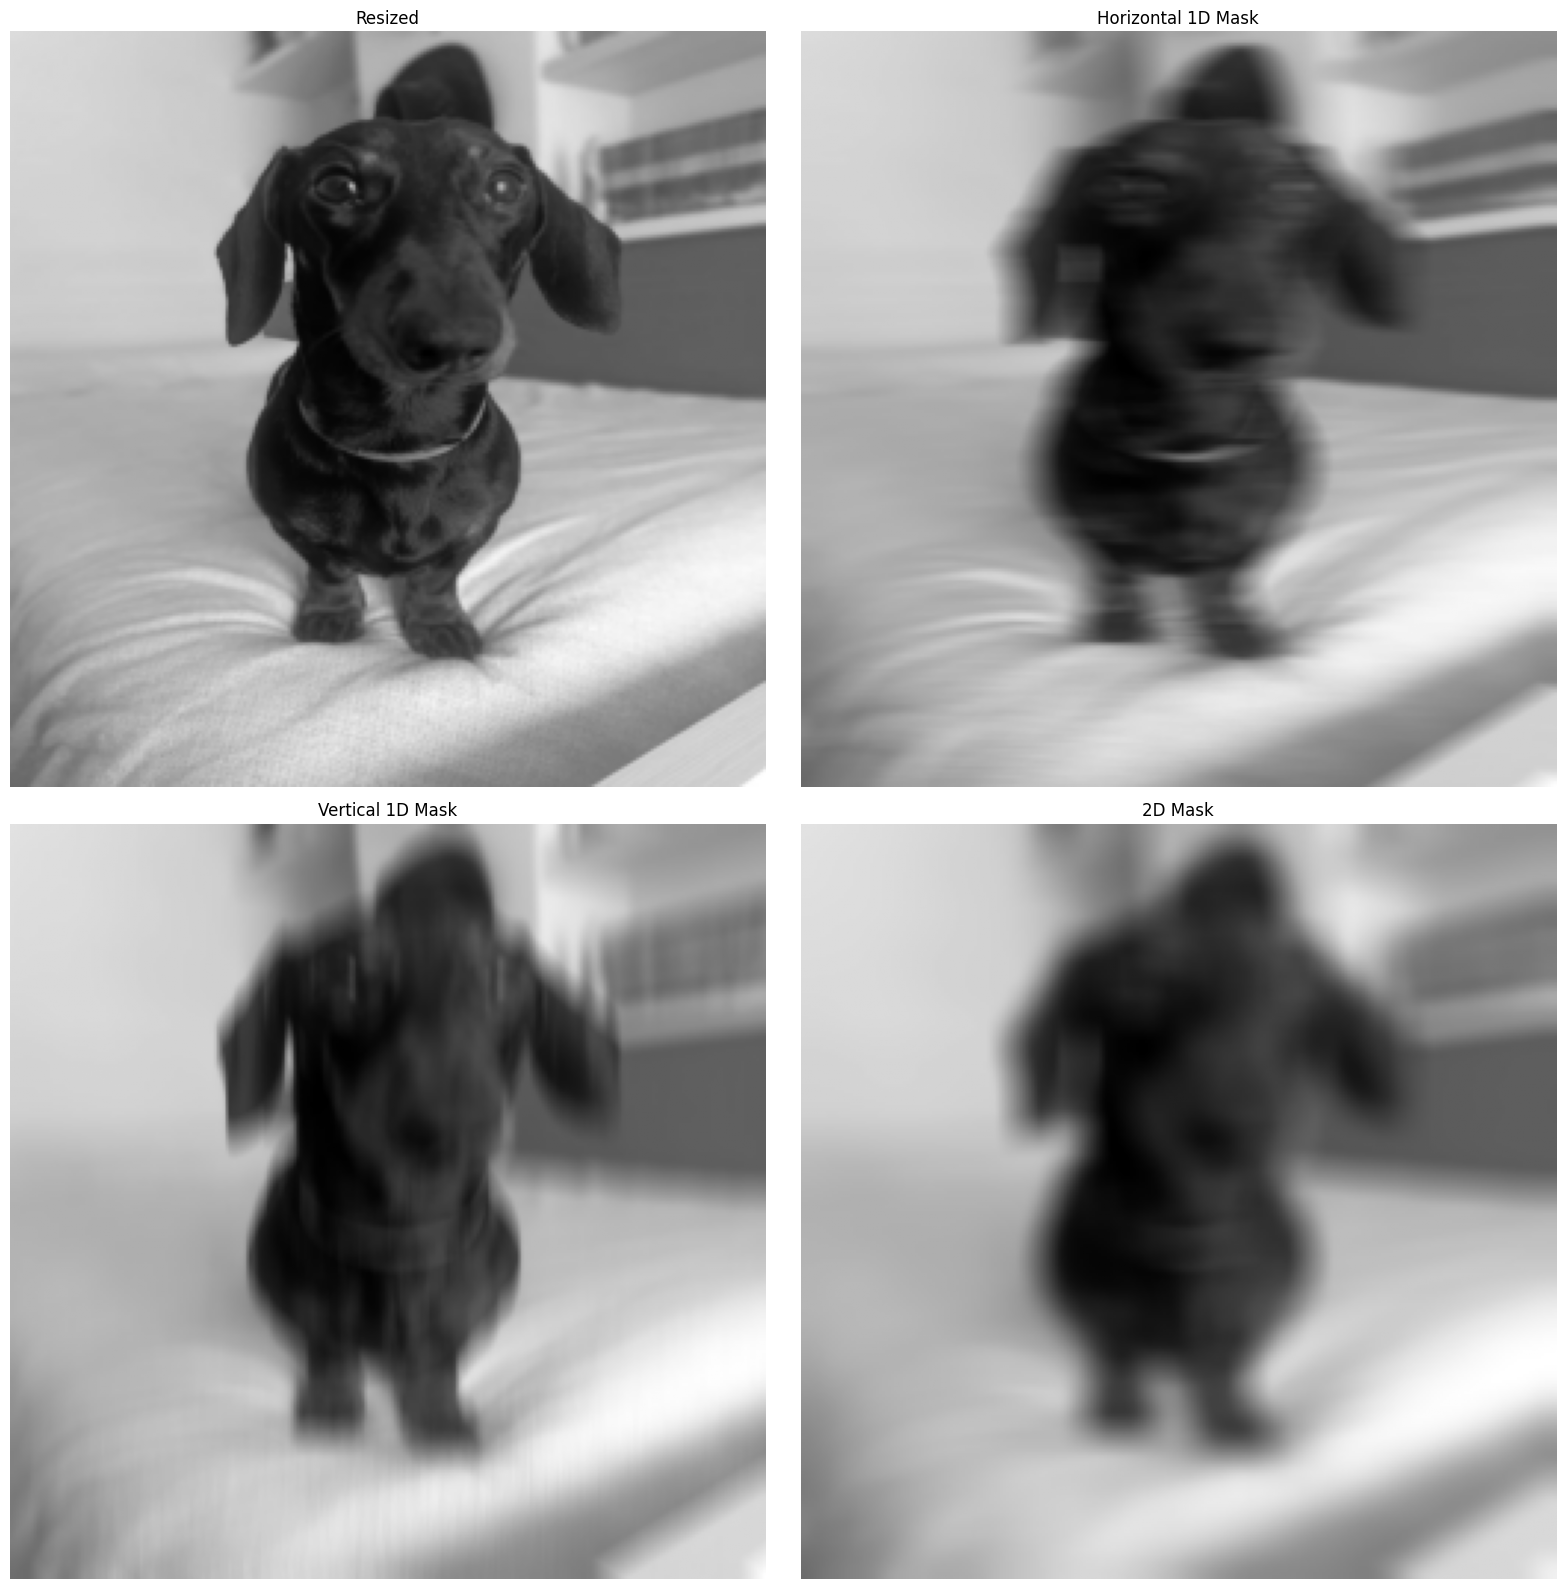

In [ ]:
# Create Figure with 4 Subplots
fig = plt.figure(figsize=(16, 16))
fig.add_subplot(2, 2, 1)
plt.imshow(oryx_gray, cmap='gray')
plt.axis("off")
plt.title("Resized")
fig.add_subplot(2, 2, 2)
plt.imshow(conv_h, cmap='gray')
plt.axis("off")
plt.title("Horizontal 1D Mask")
fig.add_subplot(2, 2, 3)
plt.imshow(conv_v, cmap='gray')
plt.axis("off")
plt.title("Vertical 1D Mask")
fig.add_subplot(2, 2, 4)
plt.imshow(conv_2d, cmap='gray')
plt.axis("off")
plt.title("2D Mask")

plt.tight_layout()
plt.show()


### Effect of the Convolution Masks

> **1D Horizontal and Vertical Masks:**
These masks smooth the image in only one direction—horizontally or vertically. This produces directional blurring while preserving more details in the perpendicular direction. As a result, the pixel intensity range is moderately reduced.

> **2D Mask:**
This mask smooths the image in both horizontal and vertical directions simultaneously, producing a stronger overall blurring effect. Because it averages a larger neighborhood of pixels, it generally reduces the pixel intensity range more significantly.


**c) RGB Image Convolution with a 2D Filter**

- Implement a function called `conv_coor(image, mask)` that applies the same 2D filter independently to each of the three RGB channels.

- Resize the original `oryx.png` image to **256 × 256 pixels**, and test your function using a **7 × 7 uniform mask**.

- Visualize the result and compare the filtered RGB image with the original image.

> Expected output is illustrated below:

<img src="images_notebook/rgb_filtered.jpg">


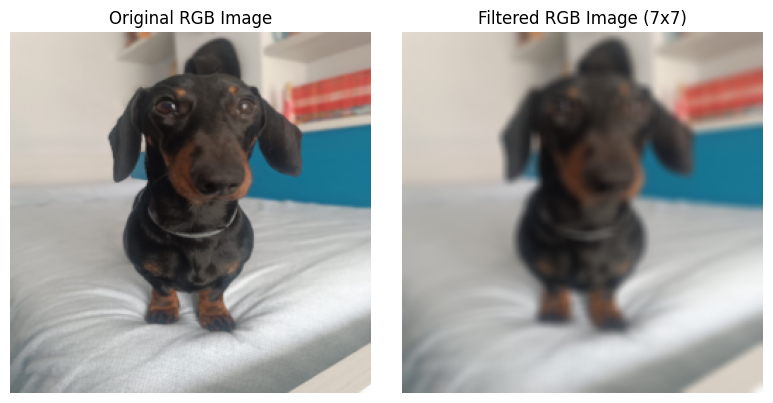

In [ ]:
def conv_coor(image, mask):
    r = image[:, :, 0]
    g = image[:, :, 1]
    b = image[:, :, 2]
    
    r_conv = ndimage.convolve(r, mask)
    g_conv = ndimage.convolve(g, mask)
    b_conv = ndimage.convolve(b, mask)
    
    filtered_image = np.dstack((r_conv, g_conv, b_conv))
    return np.clip(filtered_image, 0, 1)

mask_7x7 = np.ones((7, 7))
mask_7x7 = mask_7x7 / np.sum(mask_7x7)

filtered_oryx = conv_coor(oryx_resized, mask_7x7)
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(oryx_resized)
axes[0].set_title('Original RGB Image')
axes[0].axis('off')

axes[1].imshow(filtered_oryx)
axes[1].set_title('Filtered RGB Image (7x7)')
axes[1].axis('off')

plt.tight_layout()
plt.show()


## **2.3 Effect of image scale on convolutions**

**a)** Image Rescaling and Histogram Analysis

Resize the grayscale image `oryx_gray` and observe how the image histogram changes.

1. **Reduce** `oryx_gray` by a factor of 20 and compute its histogram using `nbins = 64`.
2. **Enlarge** `oryx_gray` by a factor of 20 and compute its histogram using `nbins = 64`.
3. Display the histograms of the original, reduced, and enlarged images side by side and compare them.

**Question:**
Are there any differences between the histograms? Explain what happens and why the histogram may change after rescaling the image.

> Expected output is illustrated below:

<img src="images_notebook/resize_impact.jpg">


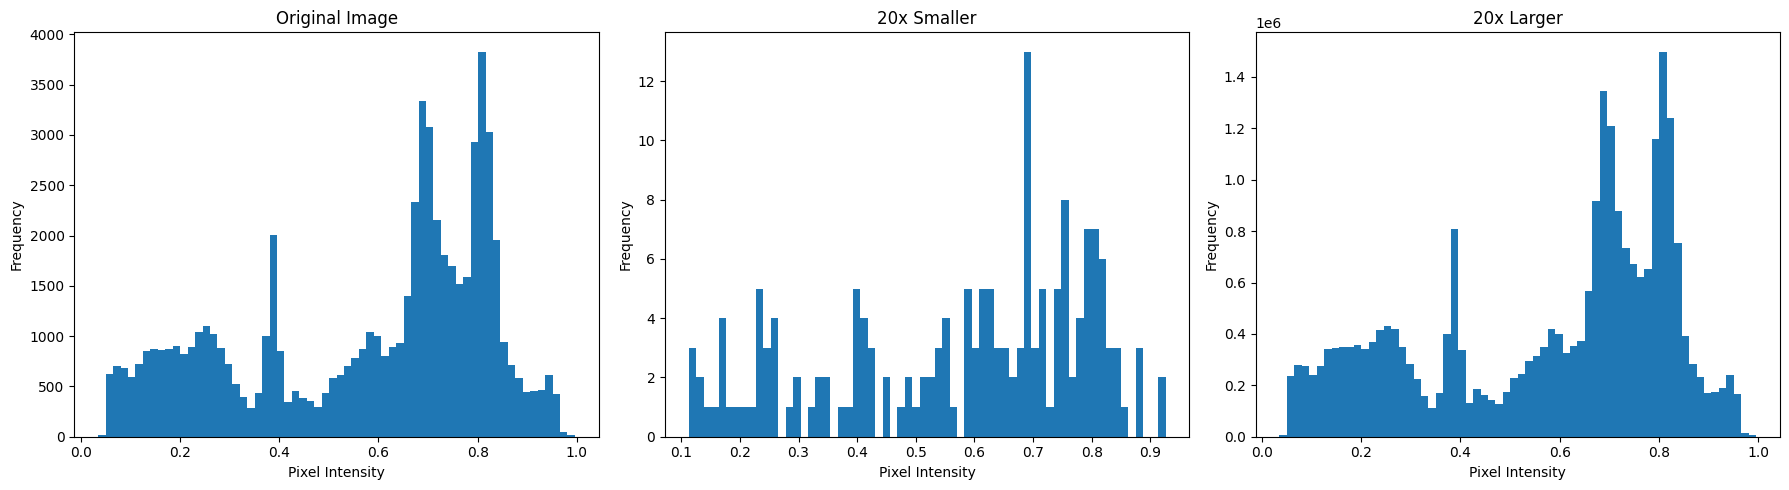

In [ ]:
from skimage.transform import rescale

# Reducir por un factor de 20 (escala = 1/20)
oryx_reduced = rescale(oryx_gray, 1/20, anti_aliasing=True)

# Ampliar por un factor de 20 (escala = 20)
oryx_enlarged = rescale(oryx_gray, 20, anti_aliasing=True)

# Mostrar los histogramas lado a lado
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
nbins = 64
axes[0].hist(oryx_gray.ravel(), bins=nbins)
axes[0].set_title('Original Image')
axes[0].set_xlabel('Pixel Intensity')
axes[0].set_ylabel('Frequency')

axes[1].hist(oryx_reduced.ravel(), bins=nbins)
axes[1].set_title('20x Smaller')
axes[1].set_xlabel('Pixel Intensity')
axes[1].set_ylabel('Frequency')

axes[2].hist(oryx_enlarged.ravel(), bins=nbins)
axes[2].set_title('20x Larger')
axes[2].set_xlabel('Pixel Intensity')
axes[2].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

**Explanation**

Sí, existen diferencias significativas entre los tres histogramas, principalmente en la escala de frecuencias (eje Y) y en la continuidad de la distribución de los datos.

*   **Imagen Reducida (20x Smaller):** 
    *   **Qué ocurre:** El histograma se vuelve muy disperso, ruidoso y presenta múltiples huecos (barras separadas). La frecuencia máxima cae drásticamente (el eje Y llega solo a 12).
    *   **Por qué:** Al reducir la imagen por un factor de 20, se elimina una inmensa cantidad de píxeles (el área total se reduce 400 veces). Al quedar tan pocos píxeles en la imagen, no hay suficientes datos estadísticos para llenar de forma continua los rangos de intensidad del histograma, provocando que muchos valores desaparezcan por completo.

*   **Imagen Ampliada (20x Larger):**
    *   **Qué ocurre:** El histograma se vuelve extremadamente denso, continuo y suavizado. La escala de frecuencia aumenta enormemente (el eje Y supera los 5 millones).
    *   **Por qué:** Al ampliar la imagen, el número total de píxeles se multiplica de forma masiva. Para rellenar esos nuevos píxeles, el software aplica algoritmos de interpolación geométrica que calculan promedios y transiciones suaves entre los colores originales. Estos cálculos generan una enorme cantidad de valores intermedios artificiales, lo que rellena el histograma haciéndolo lucir como una curva perfectamente continua y densa.

**b) Convolution and Histogram Analysis**

Apply a **7 × 7 uniform convolution mask** to the images from the previous exercise, compute their histograms, and compare the results.

1. **Plot the original `oryx_gray` image and its histogram** for reference.

2. Convolve the original `oryx_gray` image and compute its histogram.

3. Convolve the **reduced `oryx_gray` image from the previous exercise** and compute its histogram.

4. Convolve the **enlarged `oryx_gray` image from the previous exercise** and compute its histogram.

**Note:** Display the images in the **top row** and their corresponding histograms in the **bottom row**, using `nbins = 32`.

**Question:**
Compare the original and filtered images and their histograms. What differences do you observe, and why do these differences occur?

> Expected output is illustrated below:

<img src="images_notebook/oryx_filtered2.jpg">

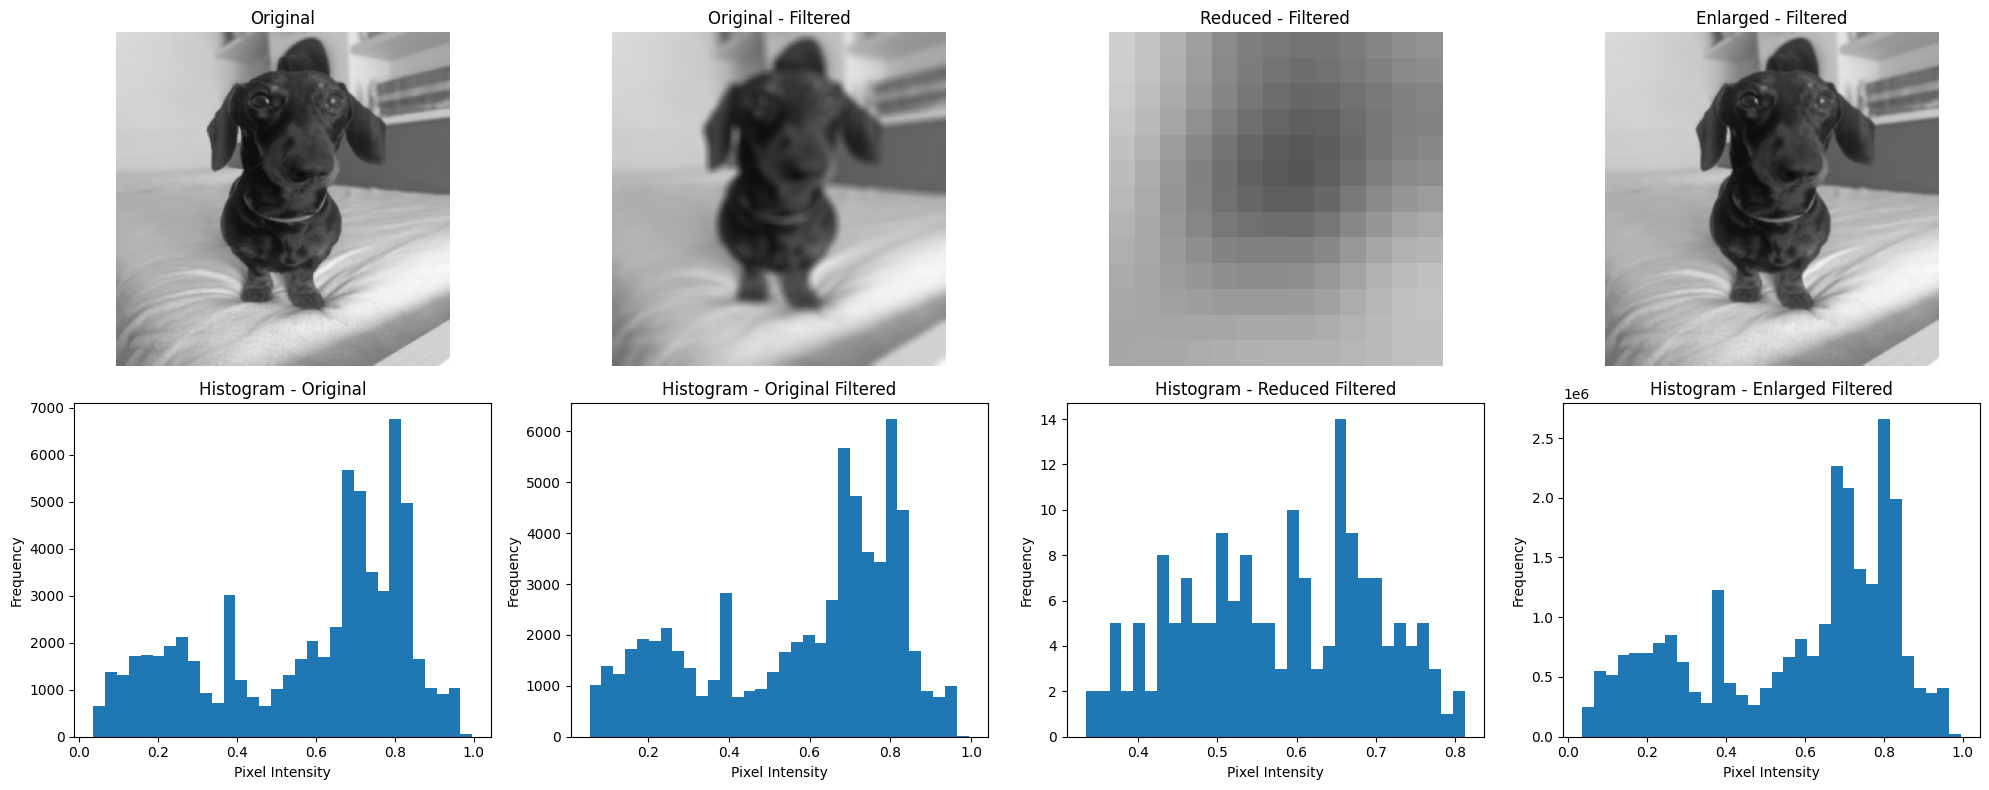

In [ ]:
# Definir la máscara uniforme de 7x7 y normalizarla
mask_7x7 = np.ones((7, 7))
mask_7x7 = mask_7x7 / np.sum(mask_7x7)

# Aplicar la convolución a las 3 imágenes
oryx_filtered = ndimage.convolve(oryx_gray, mask_7x7)
reduced_filtered = ndimage.convolve(oryx_reduced, mask_7x7)
enlarged_filtered = ndimage.convolve(oryx_enlarged, mask_7x7)

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
nbins = 32
axes[0, 0].imshow(oryx_gray, cmap='gray', vmin=0, vmax=1)
axes[0, 0].set_title('Original')
axes[0, 0].axis('off')
axes[0, 1].imshow(oryx_filtered, cmap='gray', vmin=0, vmax=1)
axes[0, 1].set_title('Original - Filtered')
axes[0, 1].axis('off')
axes[0, 2].imshow(reduced_filtered, cmap='gray', vmin=0, vmax=1)
axes[0, 2].set_title('Reduced - Filtered')
axes[0, 2].axis('off')
axes[0, 3].imshow(enlarged_filtered, cmap='gray', vmin=0, vmax=1)
axes[0, 3].set_title('Enlarged - Filtered')
axes[0, 3].axis('off')

axes[1, 0].hist(oryx_gray.ravel(), bins=nbins)
axes[1, 0].set_title('Histogram - Original')
axes[1, 0].set_xlabel('Pixel Intensity')
axes[1, 0].set_ylabel('Frequency')
axes[1, 1].hist(oryx_filtered.ravel(), bins=nbins)
axes[1, 1].set_title('Histogram - Original Filtered')
axes[1, 1].set_xlabel('Pixel Intensity')
axes[1, 1].set_ylabel('Frequency')
axes[1, 2].hist(reduced_filtered.ravel(), bins=nbins)
axes[1, 2].set_title('Histogram - Reduced Filtered')
axes[1, 2].set_xlabel('Pixel Intensity')
axes[1, 2].set_ylabel('Frequency')
axes[1, 3].hist(enlarged_filtered.ravel(), bins=nbins)
axes[1, 3].set_title('Histogram - Enlarged Filtered')
axes[1, 3].set_xlabel('Pixel Intensity')
axes[1, 3].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

**Explanation**

Las principales diferencias observadas demuestran los efectos espaciales y estadísticos de aplicar un filtro de media a diferentes escalas[cite: 12].

**Comparación de las imágenes:**

*   La imagen original presenta contornos definidos, mientras que la original filtrada exhibe un marcado desenfoque (blurring)[cite: 12].
*   Esta diferencia ocurre porque el proceso de filtrado calcula un nuevo valor para cada píxel aplicando una combinación lineal ponderada de los píxeles vecinos locales[cite: 12].
*   Al aplicar un filtro de media, se asigna un peso uniforme a todos los píxeles dentro de la máscara, lo que inevitablemente difumina y borra los bordes nítidos y los detalles finos de la imagen[cite: 12].

**Comparación de los histogramas:**

*   El histograma original muestra una distribución amplia y detallada con transiciones nítidas[cite: 12].
*   En el histograma de la imagen original filtrada, los picos se agrupan y la distribución se suaviza[cite: 12]. Esto se debe a que el promediado elimina las altas frecuencias y suaviza las transiciones abruptas de intensidad[cite: 12].
*   El histograma de la imagen reducida filtrada se vuelve discontinuo y ruidoso, presentando grandes espacios vacíos debido a la drástica disminución de píxeles disponibles para rellenar los rangos de intensidad tras el filtrado[cite: 12].
*   El histograma de la imagen ampliada filtrada muestra una curva extremadamente densa y suave, con frecuencias en la escala de millones[cite: 12]. Al aplicar el cálculo del vecindario local sobre una cantidad masiva de píxeles, se generan valores intermedios constantes que eliminan por completo las transiciones abruptas[cite: 12].


## **2.4 Image processing with weighting and non-linear filters**

**a) Generate the following kernels and apply them to the `oryx_gray` image:**

1. Generate a Gaussian kernel with σ = 1 and apply it to the image.
2. Generate Gaussian kernels with three different σ values (0.5, 2, and 3) and apply them to the image. Which σ value is the most appropriate for preserving the main objects and structures in the image?
3. Apply a median filter using different mask shapes: disk, rectangle, and diamond. Apply the median filter using different mask sizes for each shape: `disk(5)`, `rectangle(5,20)`, and `diamond(3)`, and compare their effects on the original image. What is the effect of using the different mask shapes on the original image?

> **Note:** For the disk and diamond filters, the specified value represents the **radius in pixels**, while `morphology.rectangle(5, 20)` specifies the **height and width of the rectangular structuring element (5 × 20 pixels)**.


Comment on the effects of the different filters on the original image.

**Hint:** 
- Search for the [skimage.filters function](https://scikit-image.org/docs/stable/api/skimage.filters.html) for creating the different filters.
- Also check [scikit-image — skimage.morphology documentation](https://scikit-image.org/docs/stable/api/skimage.morphology)

> Expected output is illustrated below:

<img src="images_notebook/filter.jpg">


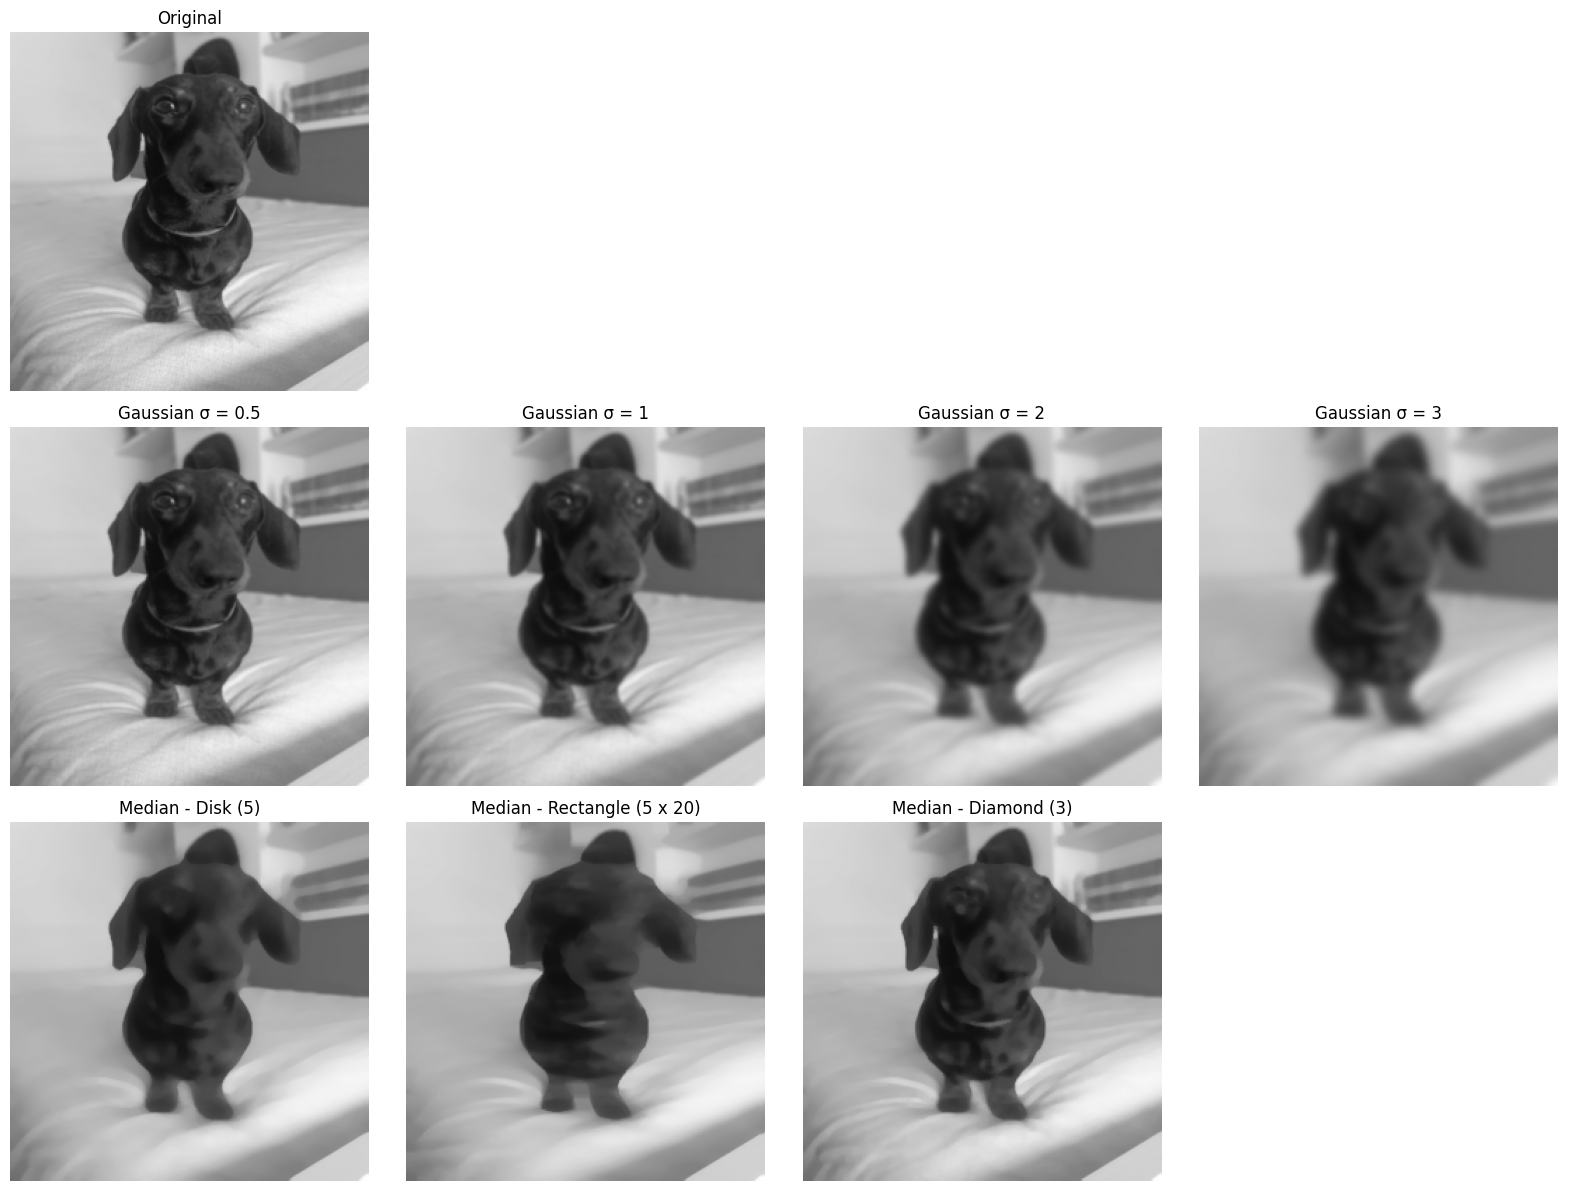

In [ ]:
from skimage import filters, img_as_float, morphology
from skimage.filters import gaussian, median
from skimage.morphology import disk, rectangle, diamond
import matplotlib.pyplot as plt

gauss_05 = gaussian(oryx_gray, sigma=0.5)
gauss_1 = gaussian(oryx_gray, sigma=1)
gauss_2 = gaussian(oryx_gray, sigma=2)
gauss_3 = gaussian(oryx_gray, sigma=3)

# 3. Aplicar filtro de Mediana con diferentes máscaras morfológicas
med_disk = median(oryx_gray, disk(5))
med_rect = median(oryx_gray, rectangle(5, 20))
med_diam = median(oryx_gray, diamond(3))

# Mostrar figura
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
nbins = 32

for ax in axes.flatten():
    ax.axis('off')

axes[0, 0].imshow(oryx_gray, cmap='gray', vmin=0, vmax=1)
axes[0, 0].set_title('Original')
axes[0, 0].axis('off')

axes[1, 0].imshow(gauss_05, cmap='gray', vmin=0, vmax=1)
axes[1, 0].set_title('Gaussian σ = 0.5')
axes[1, 0].axis('off')

axes[1, 1].imshow(gauss_1, cmap='gray', vmin=0, vmax=1)
axes[1, 1].set_title('Gaussian σ = 1')
axes[1, 1].axis('off')

axes[1, 2].imshow(gauss_2, cmap='gray', vmin=0, vmax=1)
axes[1, 2].set_title('Gaussian σ = 2')
axes[1, 2].axis('off')

axes[1, 3].imshow(gauss_3, cmap='gray', vmin=0, vmax=1)
axes[1, 3].set_title('Gaussian σ = 3')
axes[1, 3].axis('off')

axes[2, 0].imshow(med_disk, cmap='gray', vmin=0, vmax=1)
axes[2, 0].set_title('Median - Disk (5)')
axes[2, 0].axis('off')

axes[2, 1].imshow(med_rect, cmap='gray', vmin=0, vmax=1)
axes[2, 1].set_title('Median - Rectangle (5 x 20)')
axes[2, 1].axis('off')

axes[2, 2].imshow(med_diam, cmap='gray', vmin=0, vmax=1)
axes[2, 2].set_title('Median - Diamond (3)')
axes[2, 2].axis('off')

plt.tight_layout()
plt.show()

### Discussion

El uso de diferentes formas de máscara en el filtro de mediana altera drásticamente el resultado espacial sobre la imagen original:

*   **Disk (5) y Diamond (3):** Al tener formas simétricas (radiales o diagonales), suavizan la imagen manteniendo intacta la estructura general y las proporciones de los objetos principales (el animal y el entorno).
*   **Rectangle (5 x 20):** Al utilizar un elemento estructurante marcadamente rectangular (mucho más ancho que alto), se fuerza un cálculo excesivo en el eje horizontal. Esto provoca un "barrido" direccional extremo que destruye por completo las estructuras verticales de la imagen (como las patas y los cuernos del animal), distorsionando severamente su aspecto original.


b) **(Optional)** Apply the smoothing on some other images and present their results.

### **2.5 Comparison of Edge Detection Techniques**

**a)** Load the 'logo_pozo.jpg' image and visualize its contours.

<img src="images_notebook/logo_pozo.jpg" width="200" height="200">

First, convert it to gray scale. Then, apply the different contour extraction tecniques introduced during the theory session and change any parameter if necessary for detecting the edges of the image:

1. Prewitt
2. Sobel
3. Canny

Use subplot and title to visualize the results.

#### **Questions**

* What are the optimal parameter values for each method?
* Is it necessary to normalize the masks, as is commonly done when applying smoothing filters? Explain your answer.

**Hint:** Use `skimage.feature.canny` for the Canny edge detector and `skimage.filters` for the Prewitt and Sobel operators.

> Expected output is illustrated below:

<img src="images_notebook/edge.jpg">


> **Note:** Prewitt and Sobel produce grayscale images because they measure edge strength (gradient magnitude), whereas Canny applies thresholding to generate a binary image containing only the detected edges.



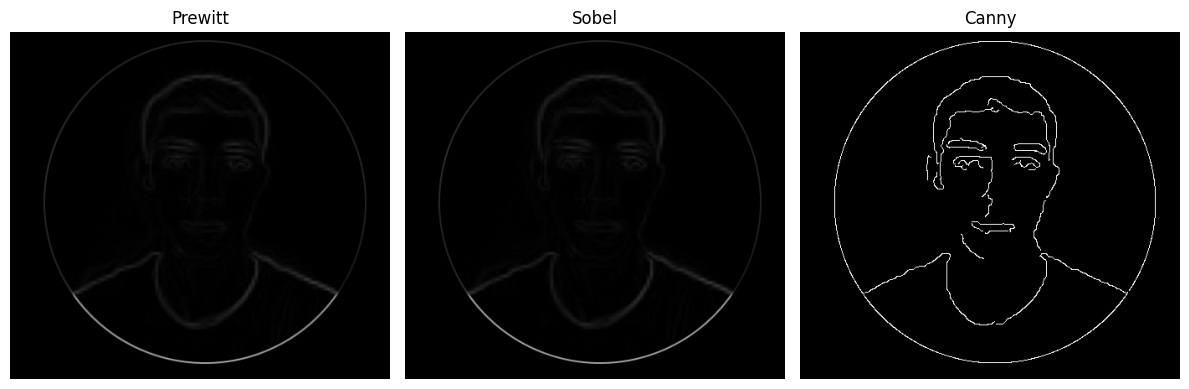

In [ ]:
import warnings
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
warnings.filterwarnings("ignore")

from skimage.feature import canny
from skimage.filters import sobel, prewitt
from skimage.color import rgb2gray

pozo = mpimg.imread("images_notebook/rico.png")
pozo = pozo[:,:, :3]
pozo = rgb2gray(pozo)

fig, axes = plt.subplots(1, 3, figsize=(12, 4)) 

axes[0].imshow(prewitt(pozo), cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Prewitt')
axes[0].axis('off')

axes[1].imshow(sobel(pozo), cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Sobel')
axes[1].axis('off')

axes[2].imshow(canny(pozo), cmap='gray', vmin=0, vmax=1)
axes[2].set_title('Canny')
axes[2].axis('off')

plt.tight_layout()
plt.show()

### Análisis de Detección de Bordes

**¿Cuáles son los valores óptimos de los parámetros para cada método?**

*   **Prewitt y Sobel:** Estos operadores clásicos basados en convolución no tienen parámetros continuos ajustables más allá de la elección de la propia matriz (típicamente de $3\times3$). El método de Sobel suele ser preferido empíricamente porque incorpora pesos mayores en su centro (ej. 2 y -2), lo que proporciona un ligero efecto de suavizado interno que lo hace más robusto frente al ruido en comparación con Prewitt.
*   **Canny:** Al ser un algoritmo de múltiples etapas, carece de valores óptimos universales; dependen de la imagen específica:
    *   **Suavizado Gaussiano ($\sigma$):** Un $\sigma$ bajo (ej. $1.0$) es óptimo para capturar bordes finos y detallados en imágenes limpias. Un $\sigma$ más alto es necesario si la imagen tiene ruido, aunque engrosará los bordes.
    *   **Umbrales de Histéresis (Alto y Bajo):** El umbral alto determina los píxeles que son bordes seguros, y el bajo determina qué píxeles adyacentes se conservan para dar continuidad a la línea. Deben ajustarse empíricamente según el contraste de la imagen para evitar detectar texturas irrelevantes (falsos positivos) o perder líneas continuas (falsos negativos).

**¿Es necesario normalizar las máscaras, como se hace comúnmente al aplicar filtros de suavizado?**

*   **No, es fundamentalmente distinto.** Para los filtros de suavizado, la suma de todos los pesos del kernel debe ser obligatoriamente **1** para que el brillo global de la imagen no cambie drásticamente[cite: 16].
*   Sin embargo, las máscaras de detección de bordes (como Sobel o Prewitt) son aproximaciones de derivadas espaciales. Por diseño empírico y matemático, la suma de todos sus elementos debe ser exactamente **0**.
*   **¿Por qué?** Esto garantiza que al aplicar la máscara sobre un área de intensidad constante (una región lisa sin contornos ni texturas), el resultado numérico sea cero (píxel negro). De esta manera, el filtro solo produce una respuesta (valores mayores a cero) en las zonas donde existen cambios abruptos de intensidad, logrando aislar y resaltar únicamente los bordes.

**b)**	Repeat the experiment with other images, you can use the ones included in the folder **images** (`cr.jpg` and `messi.jpg`). 
- Comment if some parameter needs to be changed for the different images.

#### **Questions**

- Does applying smoothing before edge detection improve the detected contours?
- What are the limitations of the different edge detection methods?

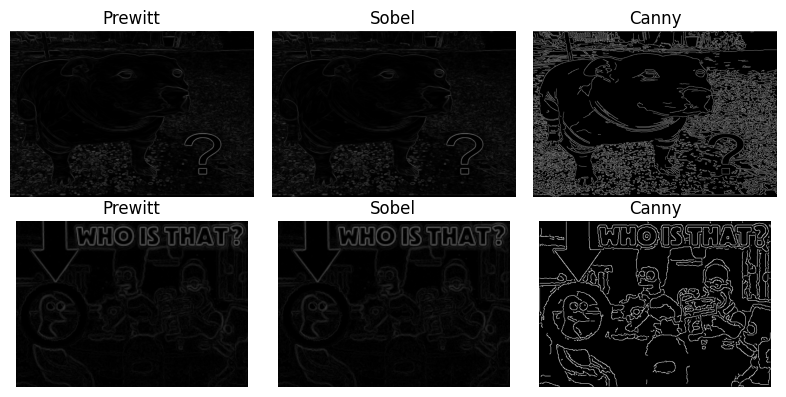

In [ ]:
messi = mpimg.imread("images_notebook/Dog.jpeg")
messi = rgb2gray(messi)

cr = mpimg.imread("images_notebook/Who.png")
cr = rgb2gray(cr)

fig, axes = plt.subplots(2, 3, figsize=(8, 4)) 

axes[0,0].imshow(prewitt(messi), cmap='gray', vmin=0, vmax=1)
axes[0,0].set_title('Prewitt')
axes[0,0].axis('off')

axes[0,1].imshow(sobel(messi), cmap='gray', vmin=0, vmax=1)
axes[0,1].set_title('Sobel')
axes[0,1].axis('off')

axes[0,2].imshow(canny(messi), cmap='gray', vmin=0, vmax=1)
axes[0,2].set_title('Canny')
axes[0,2].axis('off')

axes[1,0].imshow(prewitt(cr), cmap='gray', vmin=0, vmax=1)
axes[1,0].set_title('Prewitt')
axes[1,0].axis('off')

axes[1,1].imshow(sobel(cr), cmap='gray', vmin=0, vmax=1)
axes[1,1].set_title('Sobel')
axes[1,1].axis('off')

axes[1,2].imshow(canny(cr), cmap='gray', vmin=0, vmax=1)
axes[1,2].set_title('Canny')
axes[1,2].axis('off')

plt.tight_layout()
plt.show()


### Discussion

**1. Does applying smoothing before edge detection improve the detected contours?**

> **Sí, generalmente mejora de forma significativa los resultados.** Los algoritmos de detección de bordes se basan en el cálculo de derivadas espaciales (gradientes), las cuales son extremadamente sensibles a las variaciones bruscas de alta frecuencia, como el ruido.
> * Al aplicar un suavizado previo (por ejemplo, un filtro Gaussiano), se actúa como un filtro paso-bajo que elimina estas altas frecuencias y el ruido. Esto evita que el algoritmo detecte "falsos bordes" causados por la textura natural de la imagen o el ruido del sensor.
> * Como se observa en los resultados (especialmente en el método de Canny, que incorpora un suavizado Gaussiano como su primera fase obligatoria), las líneas obtenidas son más limpias y continuas. 
> * Sin embargo, existe un compromiso: un suavizado excesivo (como el provocado por un filtro de media con un kernel grande) difumina y borra los bordes nítidos originales y los detalles finos de la imagen. Esto puede provocar que se pierdan contornos importantes o se desplace la ubicación exacta del borde.

**2. What are the limitations of the different edge detection methods?**

> **Análisis de limitaciones por método:**
> 
> * **Prewitt y Sobel:**
>   * **Alta sensibilidad al ruido:** Al ser operadores derivativos de un solo paso, si no se aplica un filtro de suavizado previo, cualquier ruido genera falsos picos de gradiente.
>   * **Bordes gruesos y difusos:** Producen respuestas múltiples o bordes de varios píxeles de grosor alrededor de una sola transición, ya que no incluyen técnicas de "adelgazamiento" de líneas.
>   * **Dependencia de umbrales simples:** Requieren un único umbral global para decidir qué es un borde y qué no, lo que los hace ineficaces en imágenes con iluminación desigual o bajo contraste.
> 
> * **Canny:**
>   * **Mayor costo computacional:** Es un algoritmo complejo de múltiples etapas (suavizado Gaussiano, cálculo de gradientes, supresión de no-máximos y umbralización por histéresis), lo que lo hace más lento de procesar.
>   * **Sensibilidad a los parámetros:** Sus resultados dependen en gran medida del ajuste manual. Si la desviación estándar ($\sigma$) del filtro Gaussiano es muy alta, el efecto de paso-bajo eliminará transiciones abruptas legítimas y detalles finos. Asimismo, unos umbrales de histéresis mal calibrados pueden fragmentar líneas que deberían ser continuas o, por el contrario, incluir demasiadas texturas de fondo.

**c)** Implement the Sobel and Prewitt edge detection operators manually using the `convolve` function instead of the implementations provided by `skimage.filters`.

- Define the corresponding horizontal and vertical kernels for each operator, apply them to the image using convolution, and compute the gradient magnitude from the resulting responses.

- Visualize the results and compare them with those obtained using `skimage.filters.sobel` and `skimage.filters.prewitt`.

> Expected output is illustrated below:

<img src="images_notebook/implemented_detectors.jpg">

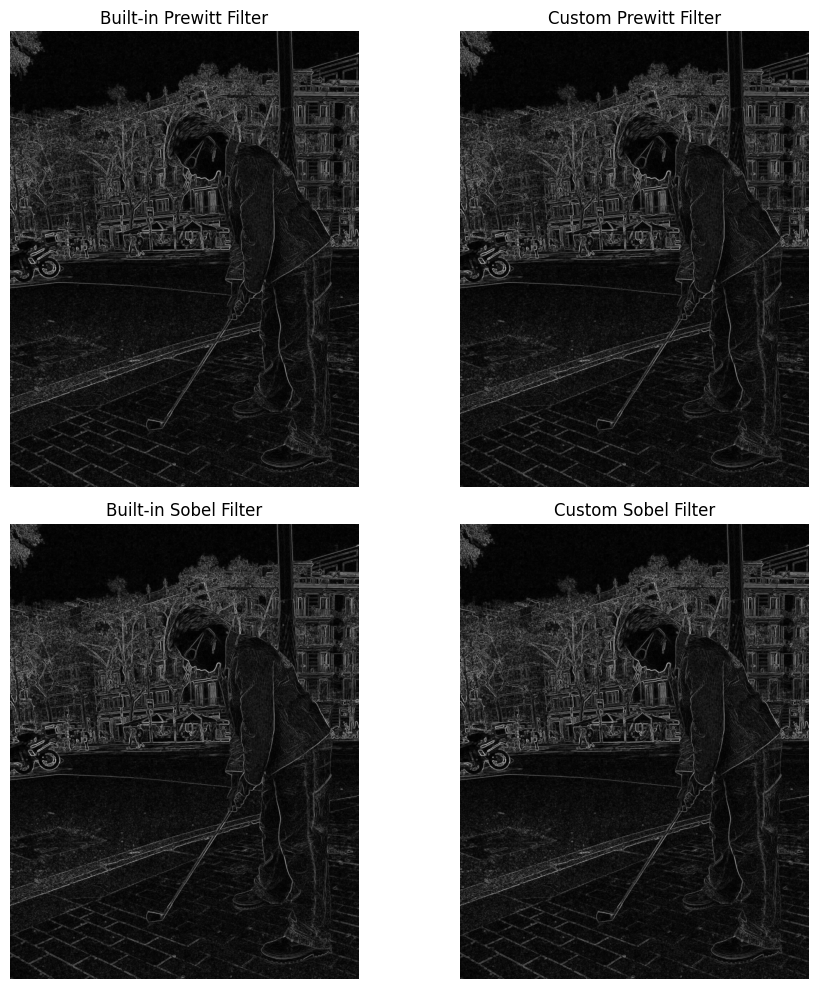

In [ ]:
from skimage.util import img_as_ubyte

# Definición de los kernels de Prewitt
prewitt_h = np.array([[-1,  0,  1],
                      [-1,  0,  1],
                      [-1,  0,  1]])

prewitt_v = np.array([[-1, -1, -1],
                      [ 0,  0,  0],
                      [ 1,  1,  1]])

# Definición de los kernels de Sobel
sobel_h = np.array([[-1,  0,  1],
                    [-2,  0,  2],
                    [-1,  0,  1]])

sobel_v = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# Aplicar convolución manual y calcular magnitud para Prewitt
prewitt_custom_h = convolve(pozo, prewitt_h)
prewitt_custom_v = convolve(pozo, prewitt_v)

prewitt_custom = np.sqrt(prewitt_custom_h**2 + prewitt_custom_v**2)

# Aplicar convolución manual y calcular magnitud para Sobel
sobel_custom_h = convolve(pozo, sobel_h)
sobel_custom_v = convolve(pozo, sobel_v)
# Magnitud del gradiente: √(Gx^2 + Gy^2)
sobel_custom = np.sqrt(sobel_custom_h**2 + sobel_custom_v**2)

# Generar resultados con las funciones integradas de skimage
prewitt_builtin = prewitt(pozo)
sobel_builtin = sobel(pozo)

# Visualización comparativa
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

axes[0, 0].imshow(prewitt_builtin, cmap='gray')
axes[0, 0].set_title('Built-in Prewitt Filter')
axes[0, 0].axis('off')

axes[0, 1].imshow(prewitt_custom, cmap='gray')
axes[0, 1].set_title('Custom Prewitt Filter')
axes[0, 1].axis('off')

axes[1, 0].imshow(sobel_builtin, cmap='gray')
axes[1, 0].set_title('Built-in Sobel Filter')
axes[1, 0].axis('off')

axes[1, 1].imshow(sobel_custom, cmap='gray')
axes[1, 1].set_title('Custom Sobel Filter')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()



### 2.6 Applying smoothing in order to obtain hybrid images

**a)** Given `./images_notebook/messi.jpg` and `./images_notebook/cr.jpg` images:

1. Plot both images.
2. Apply a low-pass filter to both of them and plot them.
3. Apply a high-pass filter to both of them and plot them.

The result should be something like:


<img src="images_notebook/Messi.png" height="200">
<img src="images_notebook/CR.png" height="200">


By applying smoothing over an image I, we apply a `low-pass` filter. The resulting image can be called L(I). If we substract the filtered one from the original image, we obtain its high frequencies, that we can call H(I), i.e. we apply a `high-pass` filter.

***H(I) = I - L(I)***

***Hint:*** In order to highlight the effect, in the L(I) image you should define a lower sigma.

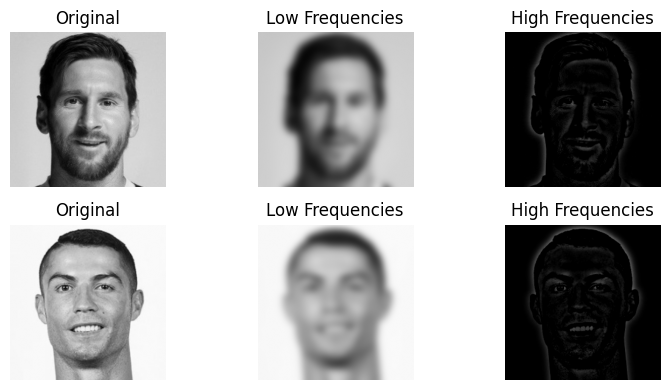

In [ ]:
# Import the necessary libraries
from skimage import io
from skimage.color import rgb2gray
from skimage.filters import gaussian
from skimage.transform import resize

messi = io.imread("images_notebook/messi.jpg")
cr = io.imread("images_notebook/cr.jpg")

# Redimensionamos para que ambas imagenes midan lo mismo
messi = resize(messi, (256, 256))
cr = resize(cr, (256, 256))

messi = rgb2gray(messi)
cr = rgb2gray(cr)

sigma_val = 6.0

# Filtro paso-bajo L(I): Aplicar suavizado gaussiano
messi_low = gaussian(messi, sigma=sigma_val)
cr_low = gaussian(cr, sigma=sigma_val)

# Filtro paso-alto H(I): Restar la imagen suavizada a la original (I - L(I))
# Usamos np.clip para asegurar que los valores se mantengan en el rango válido [0, 1]
messi_high = np.clip(messi - messi_low, 0, 1)
cr_high = np.clip(cr - cr_low, 0, 1)

mwaai_high = messi_high

# Mostrar Figura
fig, axes = plt.subplots(2, 3, figsize=(8, 4)) 

axes[0,0].imshow(messi, cmap='gray', vmin=0, vmax=1)
axes[0,0].set_title('Original')
axes[0,0].axis('off')

axes[0,1].imshow(messi_low, cmap='gray', vmin=0, vmax=1)
axes[0,1].set_title('Low Frequencies')
axes[0,1].axis('off')

axes[0,2].imshow(mwaai_high, cmap='gray', vmin=0, vmax=1)
axes[0,2].set_title('High Frequencies')
axes[0,2].axis('off')

axes[1,0].imshow(cr, cmap='gray', vmin=0, vmax=1)
axes[1,0].set_title('Original')
axes[1,0].axis('off')

axes[1,1].imshow(cr_low, cmap='gray', vmin=0, vmax=1)
axes[1,1].set_title('Low Frequencies')
axes[1,1].axis('off')

axes[1,2].imshow(cr_high, cmap='gray', vmin=0, vmax=1)
axes[1,2].set_title('High Frequencies')
axes[1,2].axis('off')

plt.tight_layout()
plt.show()


**b)** Create hybrid images and visualize them. A hybrid image is obtained by combining the low and high frequencies of the image, i.e. combining the results obtained by the `low-pass` and `high-pass` filters.

<img src="images_notebook/Fusion.gif" width="400" height="400">

***Hybrid (I1, I2) = L(I1) + H(I2)***



### Exercise: Create Hybrid Images

Using the low- and high-frequency components obtained from the `messi` and `cr` images, create two hybrid images.

1. Create **Hybrid Image 1** by combining the low-frequency component of `cr` with the high-frequency component of `messi`, giving both components equal weight (`0.5`).
2. Create **Hybrid Image 2** by combining the low-frequency component of `messi` with the high-frequency component of `cr`, also giving both components equal weight (`0.5`).
3. Multiply each result by `2` to compensate for the averaging.
4. Display both hybrid images side by side in a `1 × 2` grid, without axes, and with appropriate titles.

> Expected result is shown below:

<img src="images_notebook/Hybrid.png" height="200">


> Hybrid images can be used in **visual illusions, art and design, advertising, visual perception research, and computer vision applications**, where different details are perceived at different viewing distances.


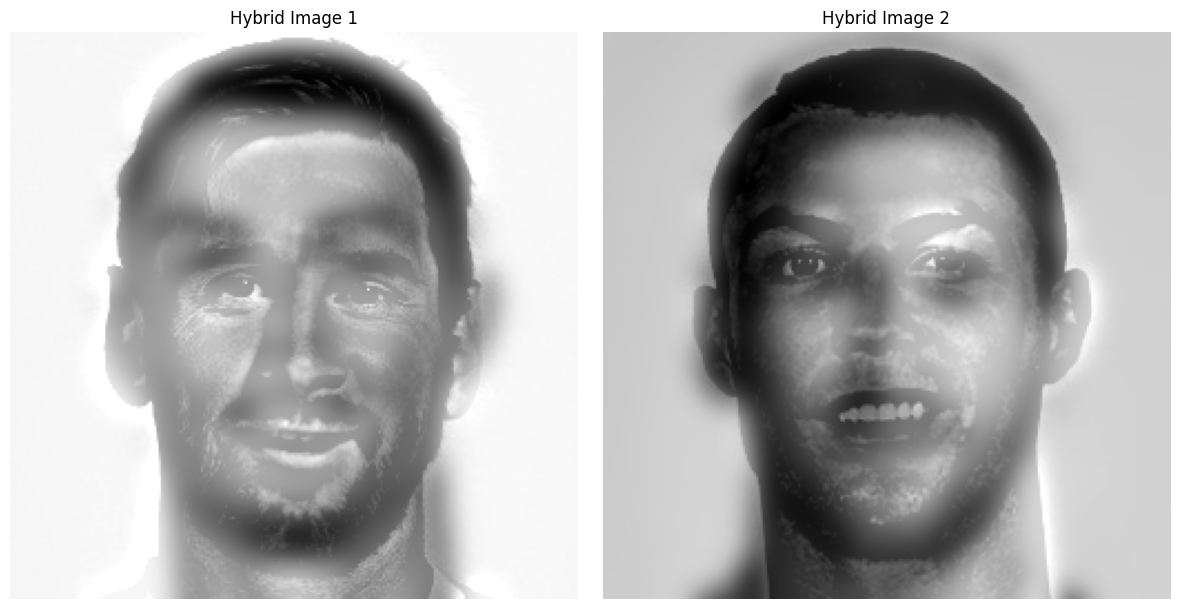

In [ ]:
# low-frequency de CR y high-frequency de Messi (pesos 0.5)
hybrid1 = (cr_low * 0.5) + (messi_high * 0.5)

# low-frequency de Messi y high-frequency de CR (pesos 0.5)
hybrid2 = (messi_low * 0.5) + (cr_high * 0.5)

# Multiplicar cada resultado por 2 para compensar el promediado
hybrid1 = hybrid1 * 2
hybrid2 = hybrid2 * 2

# Es buena práctica asegurar que los valores finales no excedan el rango [0, 1] tras la suma
hybrid1 = np.clip(hybrid1, 0, 1)
hybrid2 = np.clip(hybrid2, 0, 1)

# Mostrar Figura
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(hybrid1, cmap='gray')
axes[0].set_title('Hybrid Image 1')
axes[0].axis('off')

axes[1].imshow(hybrid2,  cmap='gray')
axes[1].set_title('Hybrid Image 2')
axes[1].axis('off')

plt.tight_layout()
plt.show()


## **2.7 Anonimization of sensitive information**

One of the important problems in Computer Vision as a science that manages data (images and videos) is the anonimization of sensitive information appearing in the images.
For example, it is common in applications like Google Street View, where the faces and license plates are anonymized.
The file `./images_notebook/car.png` contains two cars. Anonimize the license plates of the cars using the techniques learned in this practicum.

Modify only the license plates of the cars, keeping the rest of the image unchanged.

Expected result is illustrated below:

<img src="images_notebook/anonimyzed.jpg" height="350">

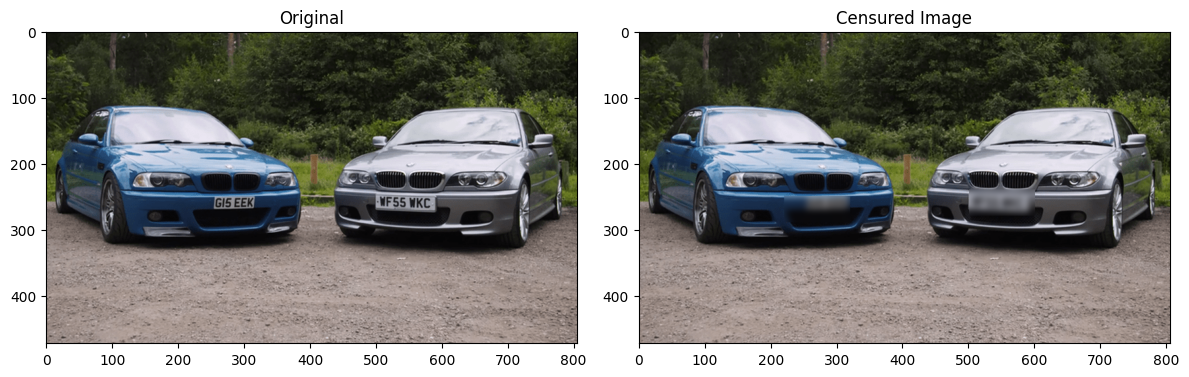

In [ ]:
cars = io.imread("images_notebook/car.png")

cars_censured = cars.copy()

# Coordenadas estimadas para el coche azul
y1, y2, x1, x2 = 250, 290, 220, 320
# Coordenadas estimadas para el coche gris
y3, y4, x3, x4 = 240, 280, 500, 600

# Aplicar el filtro gaussiano solo a los recuadros (usamos un sigma alto para difuminar mucho)
plate1_blurred = gaussian(cars[y1:y2, x1:x2], sigma=5, channel_axis=-1)
plate2_blurred = gaussian(cars[y3:y4, x3:x4], sigma=5, channel_axis=-1)

# Sobrescribir las regiones en la imagen censurada
cars_censured[y1:y2, x1:x2] = img_as_ubyte(plate1_blurred)
cars_censured[y3:y4, x3:x4] = img_as_ubyte(plate2_blurred)

# Mostrar Figura
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(cars)
axes[0].set_title('Original')
# axes[0].axis('off')

axes[1].imshow(cars_censured)
axes[1].set_title('Censured Image')
# axes[1].axis('off')

plt.tight_layout()
plt.show()

## **APENDICE: OPERACIONES CLAVE DE IMAGEN**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, color, transform, filters, feature, util
from skimage.morphology import disk, rectangle
from scipy import ndimage

# 1. LECTURA, CONVERSIÓN Y TIPOS DE DATOS

# Leer imagen
img_rgb = io.imread("images_notebook/Dog.jpeg")

# Convertir a escala de grises (devuelve valores float entre 0.0 y 1.0)
img_gray = color.rgb2gray(img_rgb)

# Convertir explícitamente a float (útil antes de hacer restas o sumas de imágenes)
img_float = util.img_as_float(img_rgb) 

# Convertir de vuelta a enteros 0-255 (útil para guardar o si un filtro lo exige)
img_uint8 = util.img_as_ubyte(img_gray)


# 2. REDIMENSIONAR E INVERTIR (El truco del examen anterior)

# Redimensionar a un tamaño exacto (Alto, Ancho)
img_resized = transform.resize(img_gray, (256, 256))

# INVERTIR UNA IMAGEN (Calcular el negativo)
# Si la imagen es float [0.0, 1.0]:
img_invertida_float = 1.0 - img_gray
# Si la imagen es entera uint8 [0, 255]:
img_invertida_uint = 255 - img_uint8


# 3. FILTRADO ESPACIAL (SUAVIZADO Y RUIDO)

# Filtro Gaussiano (Filtro paso-bajo, suaviza de forma natural)
# channel_axis=-1 es necesario si la imagen tiene color (RGB)
img_gauss = filters.gaussian(img_rgb, sigma=2.0, channel_axis=-1)

# Filtro de Mediana (Ideal para ruido sal y pimienta, preserva bordes)
# Se le pasa la forma del vecindario (ej. un disco de radio 3)
img_median = filters.median(img_gray, disk(3))

# Convolución manual con una máscara (ej. filtro de media de 3x3)
mascara_media = np.ones((3, 3)) / 9.0  # ¡Importante dividir por la suma!
img_convolucion = ndimage.convolve(img_gray, mascara_media)


# 4. DETECCIÓN DE BORDES Y FRECUENCIAS

# Filtros clásicos de gradiente
bordes_sobel = filters.sobel(img_gray)
bordes_prewitt = filters.prewitt(img_gray)

# Algoritmo de Canny (Bordes finos y binarios)
# sigma controla el suavizado previo (más alto = menos ruido pero bordes más gruesos)
bordes_canny = feature.canny(img_gray, sigma=1.5)

# Separar Altas Frecuencias (H) y Bajas Frecuencias (L)
img_bajas_freq = filters.gaussian(img_gray, sigma=2.0)
img_altas_freq = np.clip(img_gray - img_bajas_freq, 0, 1) # np.clip evita números < 0


# 5. RECORTE (SLICING) Y EDICIÓN DE REGIONES (ROI)

# Recortar una región de la imagen: img[y_inicio:y_fin, x_inicio:x_fin]
# Recuerda: el primer índice es la altura (Y) y el segundo la anchura (X)
y1, y2, x1, x2 = 100, 200, 150, 250
recorte = img_gray[y1:y2, x1:x2]

# Pegar un parche o censurar una zona (ej. poner un recuadro negro)
img_censurada = img_gray.copy()
img_censurada[y1:y2, x1:x2] = 0.0  # 0.0 es negro, 1.0 es blanco


# 6. HISTOGRAMAS Y VISUALIZACIÓN

# Para mostrar varias imágenes juntas
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Mostrar imagen (añadir cmap='gray' si la imagen es de un solo canal)
axes[0].imshow(img_gray, cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Imagen en Grises')
axes[0].axis('off')

# Mostrar histograma (.ravel() es obligatorio para aplanar la matriz 2D a 1D)
axes[1].hist(img_gray.ravel(), bins=64)
axes[1].set_title('Histograma')

plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'c:\\Users\\tonma\\Desktop\\VA\\P2\\p2_material\\ruta_a_la_imagen.jpg'